In [ ]:
from pathlib import Path

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
str_data = "01.원천데이터"
str_label = "02.라벨링데이터"
str_common = "01.딸기_001.설향"
str_normal = "01.정상"
str_rot = "02.역병"
str_wilt = "03.시들음병"
str_burn = "04.잎끝마름"
str_yellowing = "05.황화"

base_path = Path("/content/drive/MyDrive/멋사_CV캠프/project1_smartfarm/data/AI_HUB_strawberry/01-1.정식개방데이터/Validation")
data_path = base_path / str_data / str_common
label_path = base_path / str_label / str_common
disease_categories = [str_normal, str_rot, str_wilt, str_burn, str_yellowing]

In [ ]:
from zipfile import ZipFile

In [ ]:
cat_name_to_id = {
    '잎': 0,
    '줄기': 1,
    "화방": 2,
    "과실": 3
}

In [ ]:
part_cat = {
    0: 'leaf',
    1: 'stem',
    2: "flower",
    3: "fruit",
}

In [ ]:
disease_cat = {
    0: "normal",
    1: "rot",
    2: "wilt",
    3: "burn",
    4: "yellowing"
}

In [ ]:
output_path = Path("/content/yolo_strawberry/")
output_path.mkdir(exist_ok=True)
output_train_img_path = output_path / "images/train"
output_train_label_path = output_path / "labels/train"
output_test_img_path = output_path / "images/test"
output_test_label_path = output_path / "labels/test"
output_val_img_path = output_path / "images/val"
output_val_label_path = output_path / "labels/val"
output_train_img_path.mkdir(parents=True, exist_ok=True)
output_train_label_path.mkdir(parents=True, exist_ok=True)
output_test_img_path.mkdir(parents=True, exist_ok=True)
output_test_label_path.mkdir(parents=True, exist_ok=True)
output_val_img_path.mkdir(parents=True, exist_ok=True)
output_val_label_path.mkdir(parents=True, exist_ok=True)

In [ ]:
output_img_paths = {
    "train": output_train_img_path,
    "test": output_test_img_path,
    "val": output_val_img_path,
}
output_label_paths = {
    "train": output_train_label_path,
    "test": output_test_label_path,
    "val": output_val_label_path,
}

In [ ]:
from shutil import copy
from tqdm.notebook import tqdm
from tqdm.contrib import tzip
from zipfile import ZipFile
import zipfile
from tempfile import TemporaryDirectory
import json

In [ ]:
train_split, test_split, valid_split = 0.8, 0.1, 0.1

In [ ]:
def extract_tqdm(zip: ZipFile, path: str|Path):
    for member in tqdm(zip.infolist()):
        try:
            zip.extract(member, path)
        except zipfile.error as e:
            print(e)

In [ ]:
for disease_idx, next_disease in enumerate(tqdm(disease_categories)):
    cat_data_zip_path = base_path / str_data / f"VS_{str_common}_{next_disease}.zip"
    cat_label_zip_path = base_path / str_label / f"VL_{str_common}_{next_disease}.zip"
    with TemporaryDirectory() as data_temp_dir, TemporaryDirectory() as label_temp_dir:
        cat_data_path = Path(data_temp_dir)
        cat_label_path = Path(label_temp_dir)
        with ZipFile(cat_data_zip_path) as cat_data_zip, ZipFile(cat_label_zip_path) as cat_label_zip:
            extract_tqdm(cat_data_zip, cat_data_path)
            extract_tqdm(cat_label_zip, cat_label_path)
        image_generator = sorted(cat_data_path.glob("*.jpg"))
        label_generator = sorted(cat_label_path.glob("*.json"))
        assert len(image_generator) == len(label_generator)
        data_cnt = len(image_generator)
        for data_idx, (next_img_path, next_label_path) in enumerate(tzip(image_generator, label_generator)):
            current_progress = data_idx / data_cnt
            current_split = ""
            if current_progress <= train_split:
                current_split = "train"
            elif current_progress <= train_split + test_split:
                current_split = "test"
            else:
                current_split = "val"
            output_img_path = output_img_paths[current_split]
            output_label_path = output_label_paths[current_split]

            next_img_path: Path
            next_label_path: Path
            assert next_img_path.stem == next_label_path.stem
            img_name = next_img_path.stem + ".jpg"
            label_name = next_img_path.stem + ".txt"
            copy(next_img_path, output_img_path / img_name)
            label_data = json.loads(next_label_path.read_text(encoding="utf-8"))
            w_img = float(label_data['images']['width'])
            h_img = float(label_data['images']['height'])
            label_file_name = output_label_path / label_name
            with open(label_file_name, "w") as f:
                for next_annot in label_data['annotations']:
                    x_min, y_min, w, h = map(float, next_annot['bbox'])
                    x_center = (x_min + w / 2) / w_img
                    y_center = (y_min + h / 2) / h_img
                    w_normalized = w / w_img
                    h_normalized = h / h_img
                    annot_cat_id = int(next_annot['category_id'])
                    part_cat_name = label_data['categories'][annot_cat_id]['name']
                    part_cat_id = cat_name_to_id[part_cat_name]
                    f.write(f"{disease_idx * 4 + part_cat_id} {x_center} {y_center} {w_normalized} {h_normalized}\n")

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/7429 [00:00<?, ?it/s]

  0%|          | 0/7429 [00:00<?, ?it/s]

  0%|          | 0/7429 [00:00<?, ?it/s]

  0%|          | 0/3390 [00:00<?, ?it/s]

In [ ]:
!uv pip install --system ultralytics
!pip install -q ultralytics

Using Python 3.12.12 environment at: /usr
Resolved 50 packages in 389ms
Prepared 2 packages in 56ms
Installed 2 packages in 15ms
 + ultralytics==8.3.252
 + ultralytics-thop==2.0.18


In [ ]:
import ultralytics

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
ultralytics.checks()

Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 87.2/235.7 GB disk)


In [ ]:
category: dict[int, str] = {}
for disease_idx, disease_name in disease_cat.items():
    for part_idx, part_name in part_cat.items():
        category[disease_idx * 4 + part_idx] = f"{disease_name}_{part_name}"

In [ ]:
category

{0: 'normal_leaf',
 1: 'normal_stem',
 2: 'normal_flower',
 3: 'normal_fruit',
 4: 'rot_leaf',
 5: 'rot_stem',
 6: 'rot_flower',
 7: 'rot_fruit',
 8: 'wilt_leaf',
 9: 'wilt_stem',
 10: 'wilt_flower',
 11: 'wilt_fruit',
 12: 'burn_leaf',
 13: 'burn_stem',
 14: 'burn_flower',
 15: 'burn_fruit',
 16: 'yellowing_leaf',
 17: 'yellowing_stem',
 18: 'yellowing_flower',
 19: 'yellowing_fruit'}

In [ ]:
# ultralytics.data.utils.visualize_image_annotations(
#     "/content/yolo_strawberry/images/train/딸기_설향_시들음병_07_021_220824152855.jpg",
#     "/content/yolo_strawberry/labels/train/딸기_설향_시들음병_07_021_220824152855.txt",
#     category
# )

In [ ]:
from ultralytics import YOLO

In [ ]:
import yaml

data = {}
data['train'] = str(output_path / "images" / "train")
data['val'] = str(output_path / "images" / "valid")
data['nc'] = 20
data['names'] = list(category.values())
with open(output_path / "data.yaml", "w") as f:
    yaml.dump(data, f, default_flow_style=False)

In [ ]:
!cat {output_path / "data.yaml"}

names:
- normal_leaf
- normal_stem
- normal_flower
- normal_fruit
- rot_leaf
- rot_stem
- rot_flower
- rot_fruit
- wilt_leaf
- wilt_stem
- wilt_flower
- wilt_fruit
- burn_leaf
- burn_stem
- burn_flower
- burn_fruit
- yellowing_leaf
- yellowing_stem
- yellowing_flower
- yellowing_fruit
nc: 20
train: /content/yolo_strawberry/images/train
val: /content/yolo_strawberry/images/valid


In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")

For now I'll do that without augmentation - at least lr mirroring / mosaic is needed

In [ ]:
import os

# 현재 구조 확인
print("yolo_strawberry 폴더 내용:")
print(os.listdir('/content/yolo_strawberry'))

print("\nimages 폴더 내용:")
print(os.listdir('/content/yolo_strawberry/images'))

yolo_strawberry 폴더 내용:
['images', 'labels', 'data.yaml']

images 폴더 내용:
['valid', 'test', 'train']


In [ ]:
# val -> valid로 이름 변경 또는
import shutil
shutil.move('/content/yolo_strawberry/labels/val',
            '/content/yolo_strawberry/labels/valid')

'/content/yolo_strawberry/labels/valid'

In [ ]:
# 결과
results = model.train(data=output_path / "data.yaml", epochs=5, imgsz=640)

Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_strawberry/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train7, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, 

1️⃣  클래스별 분포


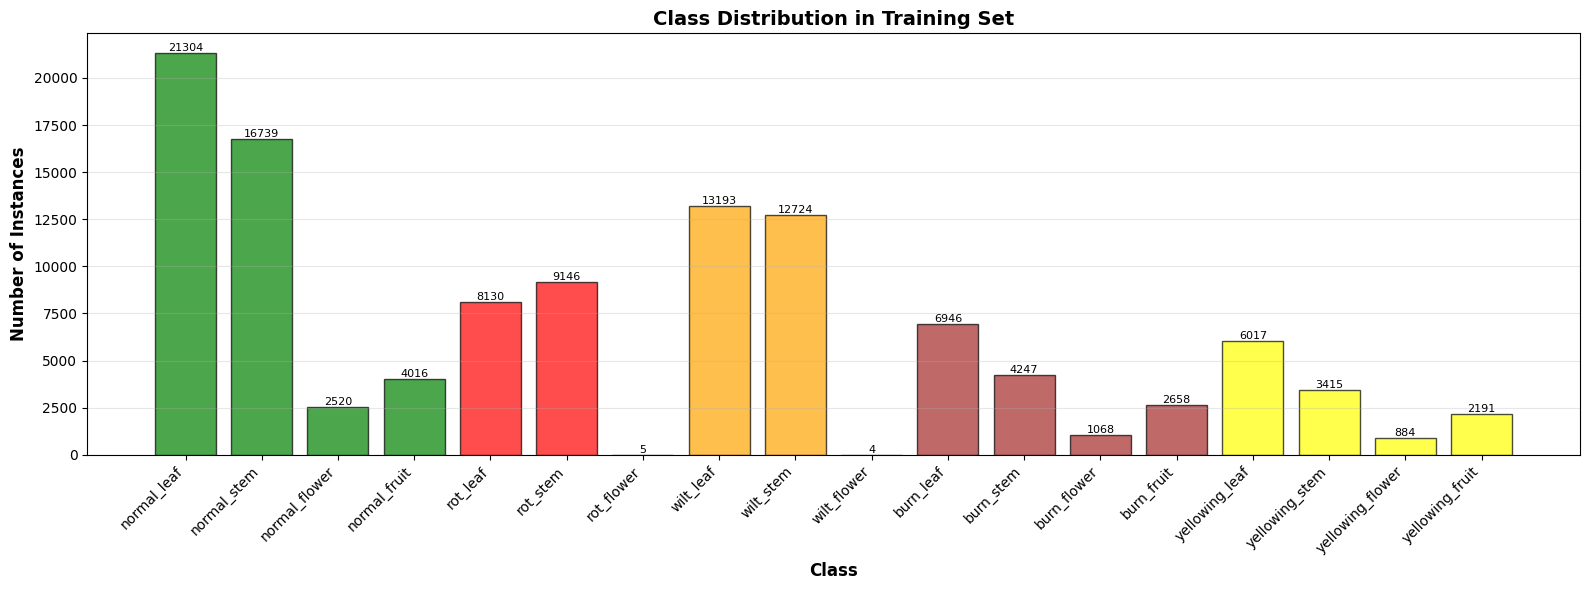


2️⃣  Disease × Part 히트맵


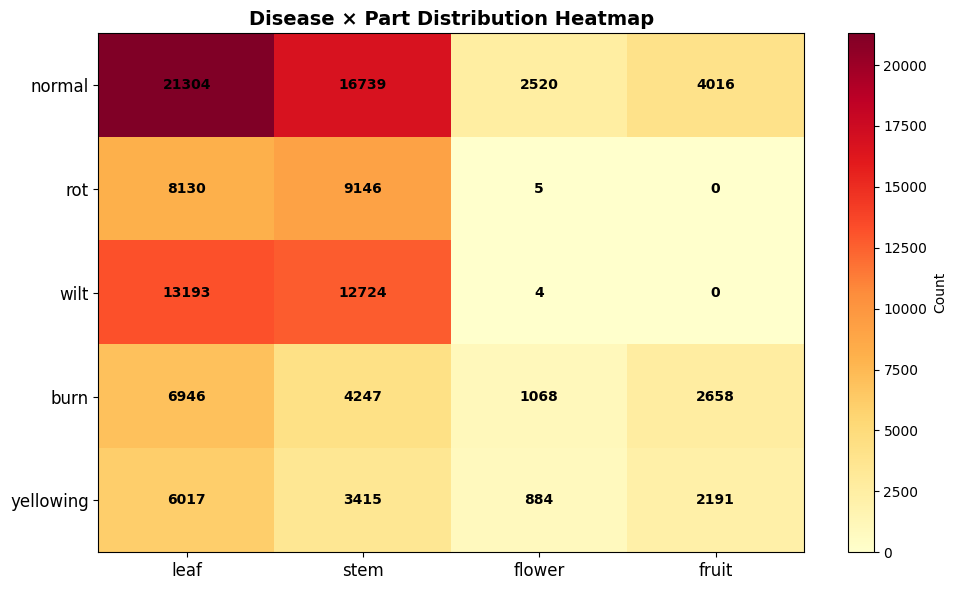


3️⃣  바운딩 박스 분석


/tmp/ipython-input-1267435103.py:139: RuntimeWarning: invalid value encountered in log10
  axes[1, 0].boxplot([np.log10(sizes)], vert=True, patch_artist=True,


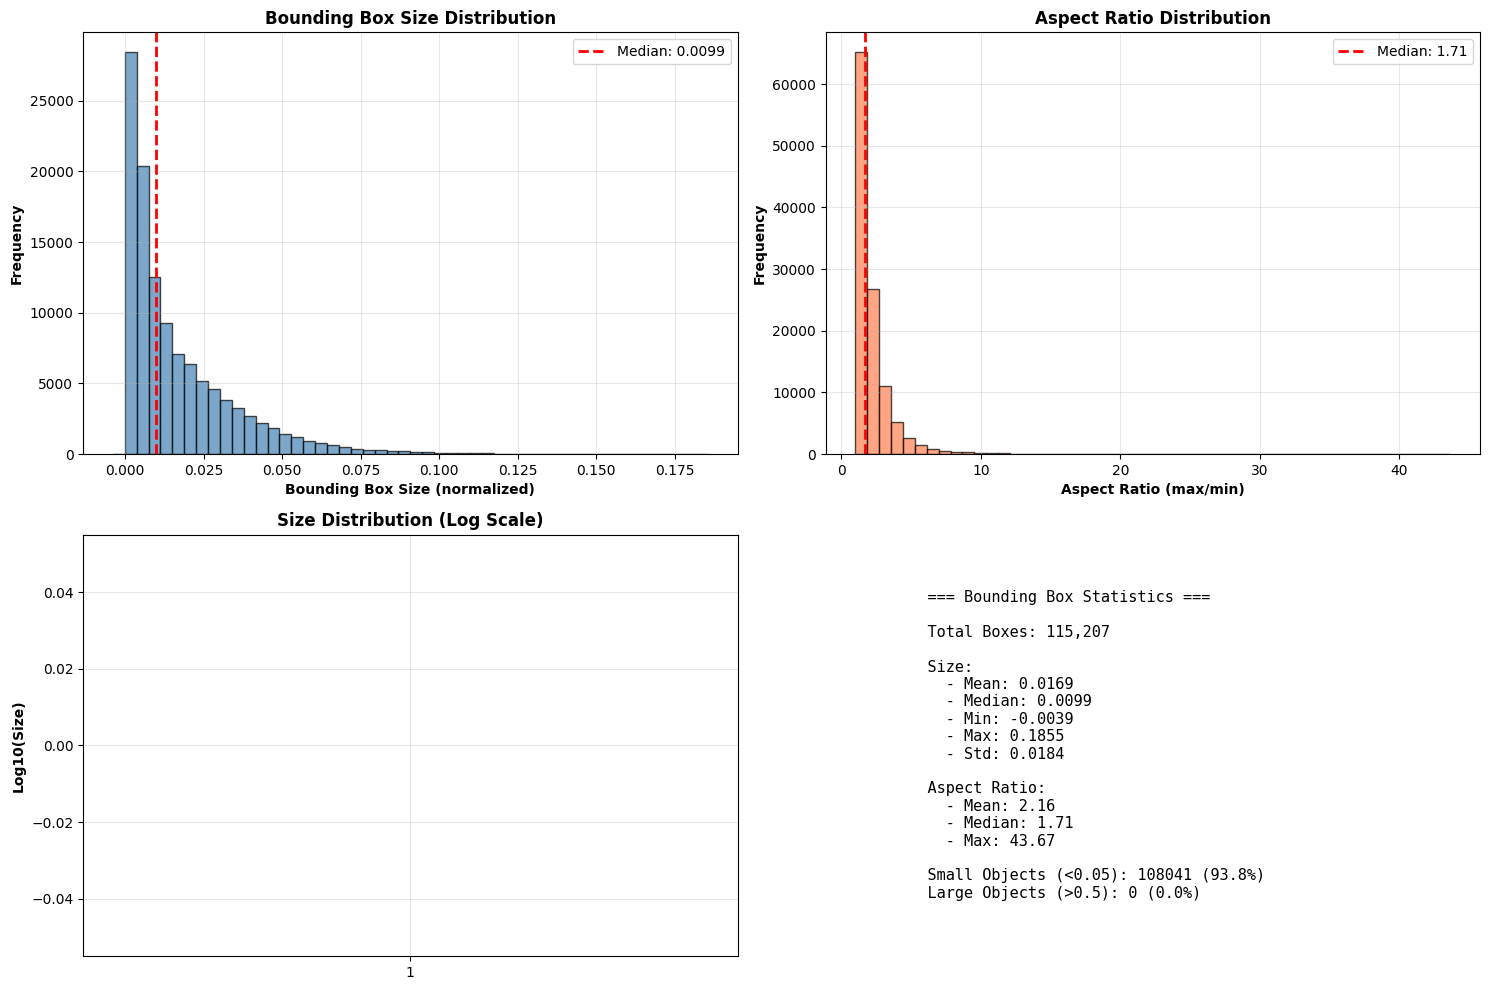


4️⃣  클래스별 크기 비교


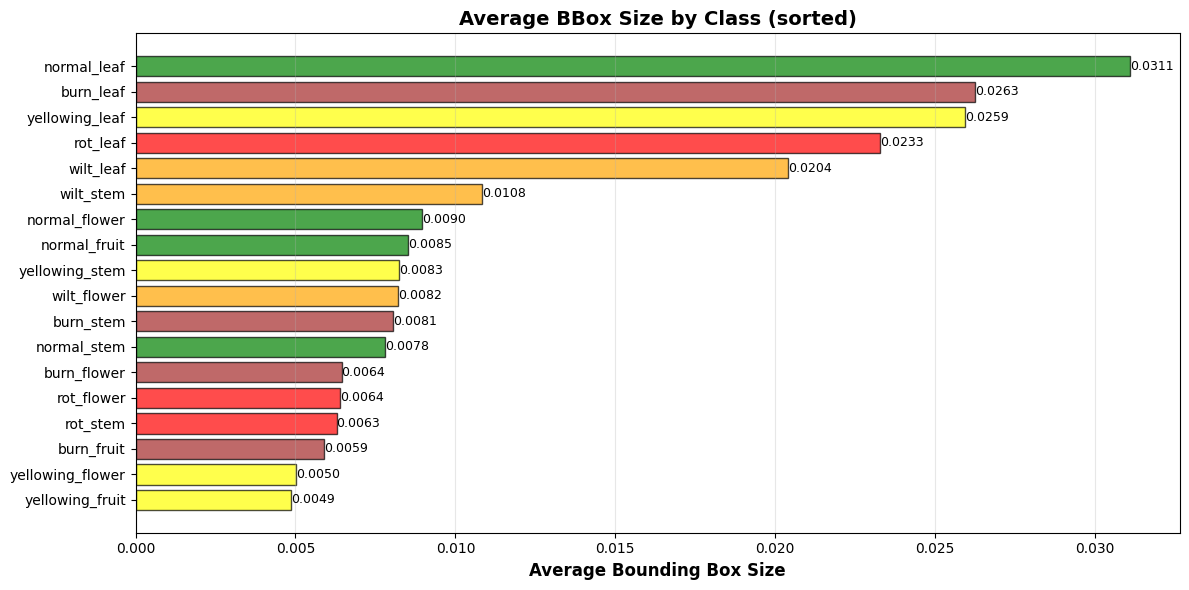


5️⃣  Train/Val/Test 분할


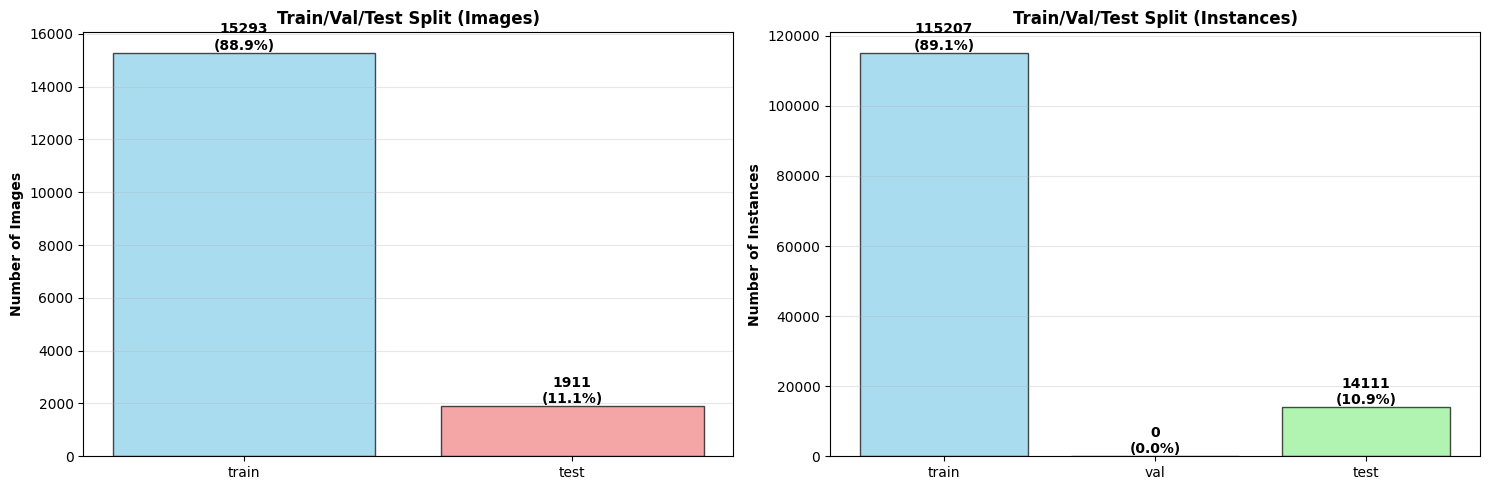


6️⃣  샘플 이미지 (바운딩 박스)


/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 46392 (\N{HANGUL SYLLABLE DDAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 49444 (\N{HANGUL SYLLABLE SEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 54693 (\N{HANGUL SYLLABLE HYANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 50669 (\N{HANGUL SYLLABLE YEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 48337 (\N{HANGUL SYLLABLE BYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1267435103.py:328: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  pl

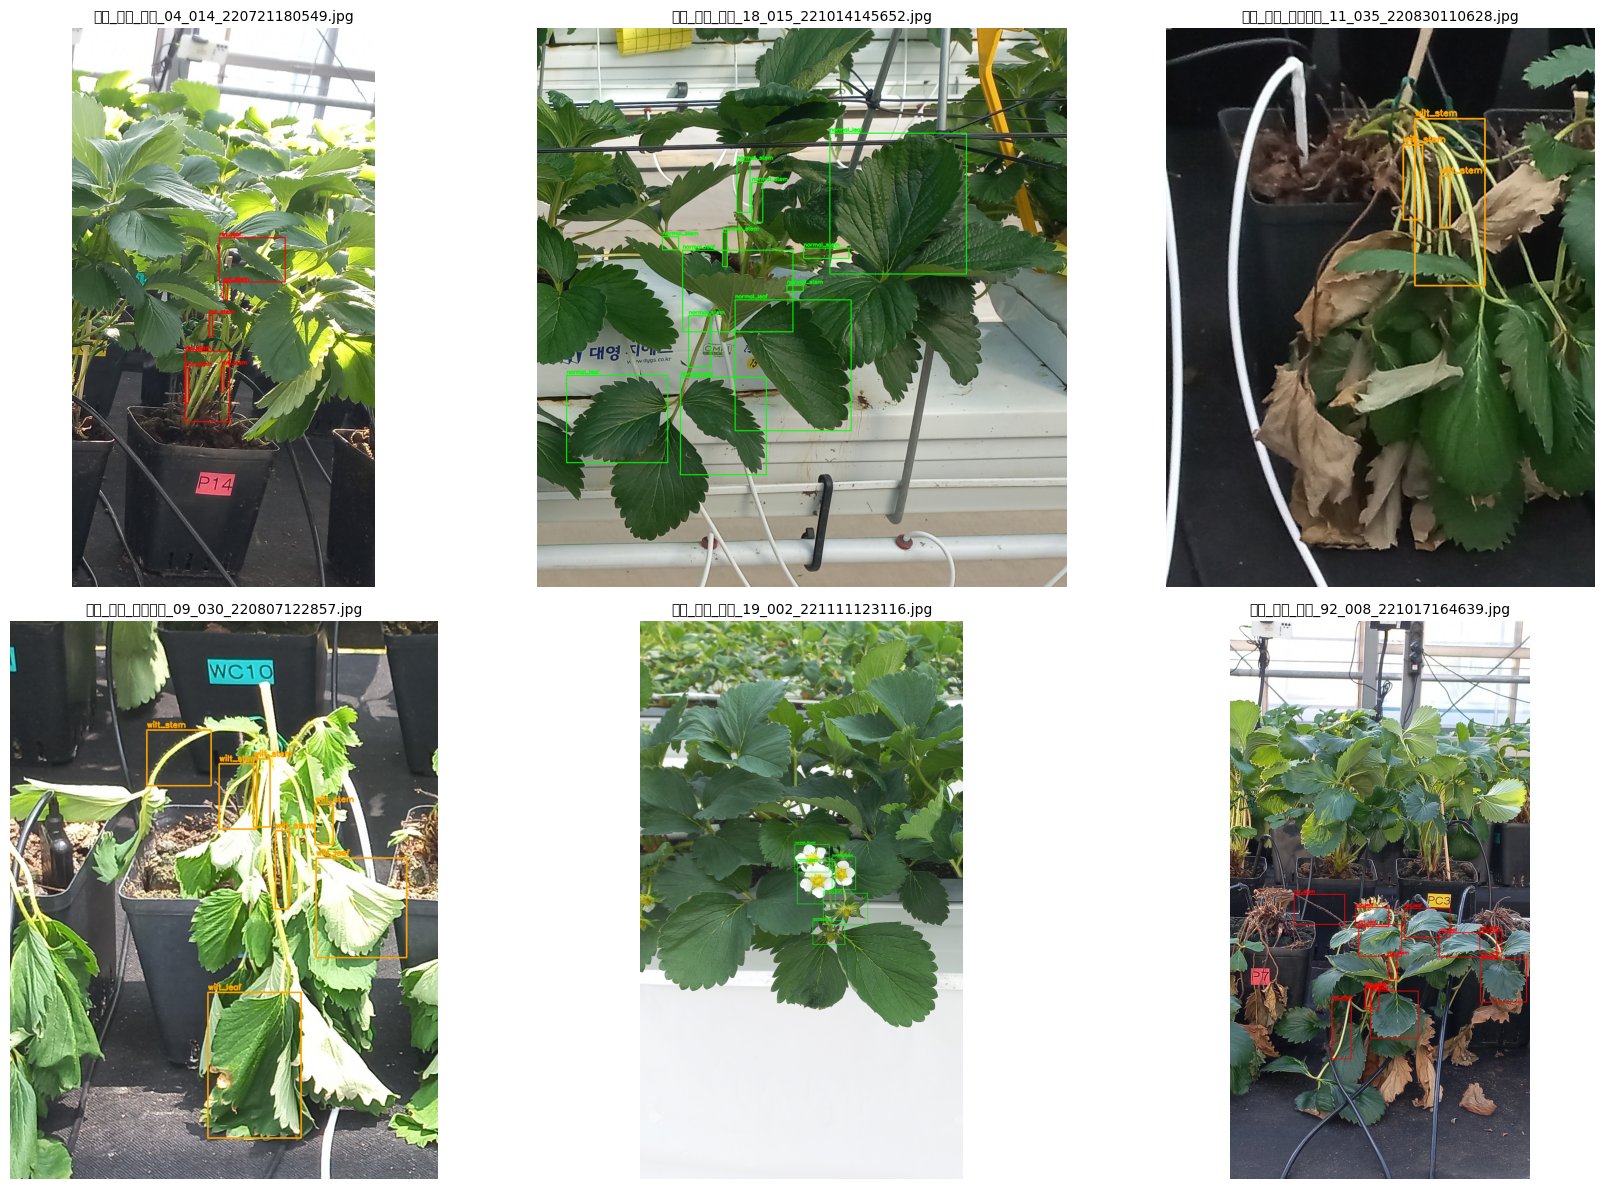

In [ ]:
# 시각화
import os
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter, defaultdict
from pathlib import Path
import cv2

# 클래스 정의
class_names = {
    0: 'normal_leaf', 1: 'normal_stem', 2: 'normal_flower', 3: 'normal_fruit',
    4: 'rot_leaf', 5: 'rot_stem', 6: 'rot_flower', 7: 'rot_fruit',
    8: 'wilt_leaf', 9: 'wilt_stem', 10: 'wilt_flower', 11: 'wilt_fruit',
    12: 'burn_leaf', 13: 'burn_stem', 14: 'burn_flower', 15: 'burn_fruit',
    16: 'yellowing_leaf', 17: 'yellowing_stem', 18: 'yellowing_flower', 19: 'yellowing_fruit'
}

# ===== 1. 클래스별 분포 시각화 =====
def visualize_class_distribution(label_dir):
    """전체 클래스별 데이터 분포"""
    class_counts = Counter()

    for label_file in Path(label_dir).glob("*.txt"):
        with open(label_file, 'r') as f:
            for line in f:
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

    # 시각화
    fig, ax = plt.subplots(figsize=(16, 6))

    classes = [class_names[i] for i in sorted(class_counts.keys())]
    counts = [class_counts[i] for i in sorted(class_counts.keys())]

    colors = ['green' if 'normal' in c else
              'red' if 'rot' in c else
              'orange' if 'wilt' in c else
              'brown' if 'burn' in c else
              'yellow' for c in classes]

    bars = ax.bar(range(len(classes)), counts, color=colors, alpha=0.7, edgecolor='black')
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.set_xlabel('Class', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Instances', fontsize=12, fontweight='bold')
    ax.set_title('Class Distribution in Training Set', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    # 값 표시
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}',
                ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.show()

    return class_counts


# ===== 2. Disease × Part 히트맵 =====
def visualize_disease_part_heatmap(label_dir):
    """Disease와 Part의 조합 분포 히트맵"""
    diseases = ['normal', 'rot', 'wilt', 'burn', 'yellowing']
    parts = ['leaf', 'stem', 'flower', 'fruit']

    # 2D 카운트 행렬
    matrix = np.zeros((len(diseases), len(parts)))

    for label_file in Path(label_dir).glob("*.txt"):
        with open(label_file, 'r') as f:
            for line in f:
                class_id = int(line.split()[0])
                disease_idx = class_id // 4
                part_idx = class_id % 4
                matrix[disease_idx, part_idx] += 1

    # 히트맵
    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(matrix, cmap='YlOrRd', aspect='auto')

    ax.set_xticks(range(len(parts)))
    ax.set_yticks(range(len(diseases)))
    ax.set_xticklabels(parts, fontsize=12)
    ax.set_yticklabels(diseases, fontsize=12)

    # 값 표시
    for i in range(len(diseases)):
        for j in range(len(parts)):
            text = ax.text(j, i, int(matrix[i, j]),
                          ha="center", va="center", color="black", fontweight='bold')

    ax.set_title('Disease × Part Distribution Heatmap', fontsize=14, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Count')
    plt.tight_layout()
    plt.show()


# ===== 3. 바운딩 박스 크기 분석 =====
def visualize_bbox_analysis(label_dir):
    """바운딩 박스 크기 및 aspect ratio 분석"""
    sizes = []
    aspect_ratios = []
    class_sizes = defaultdict(list)

    for label_file in Path(label_dir).glob("*.txt"):
        with open(label_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                class_id = int(parts[0])
                w, h = float(parts[3]), float(parts[4])
                size = w * h
                sizes.append(size)
                aspect_ratios.append(max(w, h) / min(w, h) if min(w, h) > 0 else 1)
                class_sizes[class_id].append(size)

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. 크기 히스토그램
    axes[0, 0].hist(sizes, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0, 0].axvline(np.median(sizes), color='red', linestyle='--', linewidth=2, label=f'Median: {np.median(sizes):.4f}')
    axes[0, 0].set_xlabel('Bounding Box Size (normalized)', fontweight='bold')
    axes[0, 0].set_ylabel('Frequency', fontweight='bold')
    axes[0, 0].set_title('Bounding Box Size Distribution', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    # 2. Aspect Ratio 히스토그램
    axes[0, 1].hist(aspect_ratios, bins=50, color='coral', edgecolor='black', alpha=0.7)
    axes[0, 1].axvline(np.median(aspect_ratios), color='red', linestyle='--', linewidth=2, label=f'Median: {np.median(aspect_ratios):.2f}')
    axes[0, 1].set_xlabel('Aspect Ratio (max/min)', fontweight='bold')
    axes[0, 1].set_ylabel('Frequency', fontweight='bold')
    axes[0, 1].set_title('Aspect Ratio Distribution', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    # 3. 크기 박스플롯 (로그 스케일)
    axes[1, 0].boxplot([np.log10(sizes)], vert=True, patch_artist=True,
                       boxprops=dict(facecolor='lightblue', alpha=0.7))
    axes[1, 0].set_ylabel('Log10(Size)', fontweight='bold')
    axes[1, 0].set_title('Size Distribution (Log Scale)', fontweight='bold')
    axes[1, 0].grid(alpha=0.3)

    # 4. 통계 정보
    axes[1, 1].axis('off')
    stats_text = f"""
    === Bounding Box Statistics ===

    Total Boxes: {len(sizes):,}

    Size:
      - Mean: {np.mean(sizes):.4f}
      - Median: {np.median(sizes):.4f}
      - Min: {np.min(sizes):.4f}
      - Max: {np.max(sizes):.4f}
      - Std: {np.std(sizes):.4f}

    Aspect Ratio:
      - Mean: {np.mean(aspect_ratios):.2f}
      - Median: {np.median(aspect_ratios):.2f}
      - Max: {np.max(aspect_ratios):.2f}

    Small Objects (<0.05): {sum(s < 0.05 for s in sizes)} ({sum(s < 0.05 for s in sizes)/len(sizes)*100:.1f}%)
    Large Objects (>0.5): {sum(s > 0.5 for s in sizes)} ({sum(s > 0.5 for s in sizes)/len(sizes)*100:.1f}%)
    """
    axes[1, 1].text(0.1, 0.5, stats_text, fontsize=11, family='monospace',
                    verticalalignment='center')

    plt.tight_layout()
    plt.show()

    return sizes, aspect_ratios


# ===== 4. 클래스별 크기 비교 =====
def visualize_class_size_comparison(label_dir, top_n=10):
    """클래스별 평균 바운딩 박스 크기 비교"""
    class_sizes = defaultdict(list)

    for label_file in Path(label_dir).glob("*.txt"):
        with open(label_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                class_id = int(parts[0])
                w, h = float(parts[3]), float(parts[4])
                class_sizes[class_id].append(w * h)

    # 평균 크기 계산
    avg_sizes = {class_id: np.mean(sizes) for class_id, sizes in class_sizes.items()}
    sorted_classes = sorted(avg_sizes.items(), key=lambda x: x[1])

    # 시각화
    fig, ax = plt.subplots(figsize=(12, 6))

    classes = [class_names[c[0]] for c in sorted_classes]
    sizes = [c[1] for c in sorted_classes]

    colors = ['green' if 'normal' in c else
              'red' if 'rot' in c else
              'orange' if 'wilt' in c else
              'brown' if 'burn' in c else
              'yellow' for c in classes]

    bars = ax.barh(classes, sizes, color=colors, alpha=0.7, edgecolor='black')
    ax.set_xlabel('Average Bounding Box Size', fontsize=12, fontweight='bold')
    ax.set_title('Average BBox Size by Class (sorted)', fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

    # 값 표시
    for i, bar in enumerate(bars):
        width = bar.get_width()
        ax.text(width, bar.get_y() + bar.get_height()/2.,
                f'{width:.4f}',
                ha='left', va='center', fontsize=9)

    plt.tight_layout()
    plt.show()


# ===== 5. Train/Val/Test 분할 시각화 =====
def visualize_split_distribution(base_path):
    """Train/Val/Test 데이터 분할 비율"""
    splits = ['train', 'val', 'test']
    split_counts = {}
    split_class_counts = {split: Counter() for split in splits}

    for split in splits:
        label_dir = Path(base_path) / 'labels' / split
        if not label_dir.exists():
            continue

        total = 0
        for label_file in label_dir.glob("*.txt"):
            total += 1
            with open(label_file, 'r') as f:
                for line in f:
                    class_id = int(line.split()[0])
                    split_class_counts[split][class_id] += 1

        split_counts[split] = total

    # 시각화
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 1. 이미지 수 비교
    axes[0].bar(split_counts.keys(), split_counts.values(),
                color=['skyblue', 'lightcoral', 'lightgreen'],
                edgecolor='black', alpha=0.7)
    axes[0].set_ylabel('Number of Images', fontweight='bold')
    axes[0].set_title('Train/Val/Test Split (Images)', fontweight='bold')
    axes[0].grid(axis='y', alpha=0.3)

    for i, (split, count) in enumerate(split_counts.items()):
        axes[0].text(i, count, f'{count}\n({count/sum(split_counts.values())*100:.1f}%)',
                    ha='center', va='bottom', fontweight='bold')

    # 2. 인스턴스 수 비교
    split_instances = {split: sum(counts.values()) for split, counts in split_class_counts.items()}
    axes[1].bar(split_instances.keys(), split_instances.values(),
                color=['skyblue', 'lightcoral', 'lightgreen'],
                edgecolor='black', alpha=0.7)
    axes[1].set_ylabel('Number of Instances', fontweight='bold')
    axes[1].set_title('Train/Val/Test Split (Instances)', fontweight='bold')
    axes[1].grid(axis='y', alpha=0.3)

    for i, (split, count) in enumerate(split_instances.items()):
        axes[1].text(i, count, f'{count}\n({count/sum(split_instances.values())*100:.1f}%)',
                    ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()


# ===== 6. 샘플 이미지 시각화 (바운딩 박스 포함) =====
def visualize_sample_images(image_dir, label_dir, n_samples=6):
    """샘플 이미지와 바운딩 박스 시각화"""
    image_files = list(Path(image_dir).glob("*.jpg"))[:n_samples]

    rows = (n_samples + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(18, 6*rows))
    axes = axes.flatten() if n_samples > 1 else [axes]

    colors_map = {
        'normal': (0, 255, 0), 'rot': (255, 0, 0),
        'wilt': (255, 165, 0), 'burn': (139, 69, 19),
        'yellowing': (255, 255, 0)
    }

    for idx, img_file in enumerate(image_files):
        img = cv2.imread(str(img_file))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h_img, w_img = img.shape[:2]

        # 라벨 읽기
        label_file = Path(label_dir) / (img_file.stem + ".txt")
        if label_file.exists():
            with open(label_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    class_id = int(parts[0])
                    x_center, y_center, w, h = map(float, parts[1:5])

                    # 픽셀 좌표로 변환
                    x1 = int((x_center - w/2) * w_img)
                    y1 = int((y_center - h/2) * h_img)
                    x2 = int((x_center + w/2) * w_img)
                    y2 = int((y_center + h/2) * h_img)

                    # 색상 결정
                    class_name = class_names[class_id]
                    disease = class_name.split('_')[0]
                    color = colors_map.get(disease, (128, 128, 128))

                    # 바운딩 박스 그리기
                    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                    cv2.putText(img, class_name, (x1, y1-5),
                               cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

        axes[idx].imshow(img)
        axes[idx].set_title(f'{img_file.name}', fontsize=10)
        axes[idx].axis('off')

    # 빈 subplot 제거
    for idx in range(n_samples, len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()


# ===== 실행 =====
if __name__ == "__main__":
    # 경로 설정
    base_path = "/content/yolo_strawberry"
    train_label_dir = f"{base_path}/labels/train"
    train_image_dir = f"{base_path}/images/train"

    print("=" * 60)
    print("1️⃣  클래스별 분포")
    print("=" * 60)
    class_counts = visualize_class_distribution(train_label_dir)

    print("\n" + "=" * 60)
    print("2️⃣  Disease × Part 히트맵")
    print("=" * 60)
    visualize_disease_part_heatmap(train_label_dir)

    print("\n" + "=" * 60)
    print("3️⃣  바운딩 박스 분석")
    print("=" * 60)
    sizes, aspect_ratios = visualize_bbox_analysis(train_label_dir)

    print("\n" + "=" * 60)
    print("4️⃣  클래스별 크기 비교")
    print("=" * 60)
    visualize_class_size_comparison(train_label_dir)

    print("\n" + "=" * 60)
    print("5️⃣  Train/Val/Test 분할")
    print("=" * 60)
    visualize_split_distribution(base_path)

    print("\n" + "=" * 60)
    print("6️⃣  샘플 이미지 (바운딩 박스)")
    print("=" * 60)
    visualize_sample_images(train_image_dir, train_label_dir, n_samples=6)

In [ ]:
# 불균형 클래스 제거
# Flower 전체 제거:
# - normal_flower (2,520)
# - rot_flower (5)
# - wilt_flower (4)
# - burn_flower (1,068)
# - yellowing_flower (884)

# → 15개 클래스 (leaf, stem, fruit만)
# → 가장 깔끔한 구조

In [ ]:
import os
import shutil
from pathlib import Path
from collections import Counter
from tqdm import tqdm

# ===== 설정 =====
base_path = Path("/content/yolo_strawberry")

# 제거할 클래스 ID (Option별로 선택)
# Option 1: 극소수만 제거
REMOVE_CLASSES_OPTION1 = {6, 10}  # rot_flower, wilt_flower

# Option 2: 1000개 미만 제거 (추천)
REMOVE_CLASSES_OPTION2 = {6, 10, 14}  # rot_flower, wilt_flower, burn_flower

# Option 3: Flower 전체 제거
REMOVE_CLASSES_OPTION3 = {2, 6, 10, 14, 18}  # 모든 _flower 클래스

# 선택 (여기서 변경하세요!)
REMOVE_CLASSES = REMOVE_CLASSES_OPTION2  # ← 이 부분 수정!

class_names = {
    0: 'normal_leaf', 1: 'normal_stem', 2: 'normal_flower', 3: 'normal_fruit',
    4: 'rot_leaf', 5: 'rot_stem', 6: 'rot_flower', 7: 'rot_fruit',
    8: 'wilt_leaf', 9: 'wilt_stem', 10: 'wilt_flower', 11: 'wilt_fruit',
    12: 'burn_leaf', 13: 'burn_stem', 14: 'burn_flower', 15: 'burn_fruit',
    16: 'yellowing_leaf', 17: 'yellowing_stem', 18: 'yellowing_flower', 19: 'yellowing_fruit'
}


def backup_dataset():
    """데이터셋 백업"""
    backup_path = Path("/content/yolo_strawberry_backup")
    if backup_path.exists():
        print("⚠️  백업이 이미 존재합니다. 건너뜁니다.")
        return

    print("📦 데이터셋 백업 중...")
    shutil.copytree(base_path, backup_path)
    print(f"✅ 백업 완료: {backup_path}")


def analyze_before_removal(splits=['train', 'val', 'test']):
    """제거 전 통계"""
    print("\n" + "="*60)
    print("📊 제거 전 통계")
    print("="*60)

    total_stats = Counter()
    for split in splits:
        label_dir = base_path / 'labels' / split
        if not label_dir.exists():
            continue

        split_stats = Counter()
        for label_file in label_dir.glob("*.txt"):
            with open(label_file, 'r') as f:
                for line in f:
                    class_id = int(line.split()[0])
                    split_stats[class_id] += 1
                    total_stats[class_id] += 1

        print(f"\n{split.upper()}:")
        for class_id in sorted(split_stats.keys()):
            print(f"  {class_names[class_id]:20s}: {split_stats[class_id]:6d}")

    print(f"\n전체 클래스 수: {len(total_stats)}")
    print(f"전체 인스턴스: {sum(total_stats.values()):,}")

    # 제거될 클래스 정보
    print("\n" + "="*60)
    print("🗑️  제거될 클래스")
    print("="*60)
    for class_id in sorted(REMOVE_CLASSES):
        count = total_stats.get(class_id, 0)
        print(f"  {class_names[class_id]:20s}: {count:6d} 개")

    removed_total = sum(total_stats.get(c, 0) for c in REMOVE_CLASSES)
    print(f"\n제거될 인스턴스 총합: {removed_total:,} ({removed_total/sum(total_stats.values())*100:.2f}%)")

    return total_stats


def remove_classes_from_labels(splits=['train', 'val', 'test']):
    """라벨 파일에서 특정 클래스 제거 및 ID 재매핑"""
    print("\n" + "="*60)
    print("🔧 클래스 제거 및 ID 재매핑")
    print("="*60)

    # 새로운 클래스 ID 매핑 생성
    remaining_classes = sorted([c for c in range(20) if c not in REMOVE_CLASSES])
    old_to_new = {old_id: new_id for new_id, old_id in enumerate(remaining_classes)}

    print(f"\n클래스 ID 재매핑:")
    for old_id, new_id in old_to_new.items():
        print(f"  {old_id:2d} ({class_names[old_id]:20s}) → {new_id:2d}")

    removed_files = 0
    modified_files = 0

    for split in splits:
        label_dir = base_path / 'labels' / split
        image_dir = base_path / 'images' / split

        if not label_dir.exists():
            continue

        print(f"\n처리 중: {split}...")

        for label_file in tqdm(list(label_dir.glob("*.txt"))):
            new_lines = []
            has_removed_class = False

            with open(label_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    class_id = int(parts[0])

                    if class_id in REMOVE_CLASSES:
                        has_removed_class = True
                        continue  # 이 라인 제거

                    # 클래스 ID 재매핑
                    new_class_id = old_to_new[class_id]
                    new_lines.append(f"{new_class_id} {' '.join(parts[1:])}\n")

            # 파일 업데이트
            if len(new_lines) == 0:
                # 라벨이 모두 제거됨 → 파일과 이미지 삭제
                label_file.unlink()
                img_file = image_dir / (label_file.stem + ".jpg")
                if img_file.exists():
                    img_file.unlink()
                removed_files += 1
            else:
                # 수정된 라벨 저장
                with open(label_file, 'w') as f:
                    f.writelines(new_lines)
                if has_removed_class:
                    modified_files += 1

    print(f"\n✅ 완전 제거된 파일: {removed_files}개")
    print(f"✅ 수정된 파일: {modified_files}개")

    return old_to_new


def update_data_yaml(old_to_new):
    """data.yaml 업데이트"""
    print("\n" + "="*60)
    print("📝 data.yaml 업데이트")
    print("="*60)

    new_class_names = [class_names[old_id] for old_id in sorted(old_to_new.keys())]

    yaml_content = f"""path: {base_path}
train: images/train
val: images/val
test: images/test

nc: {len(new_class_names)}
names: {new_class_names}
"""

    yaml_path = base_path / 'data.yaml'
    with open(yaml_path, 'w') as f:
        f.write(yaml_content)

    print(f"✅ data.yaml 업데이트 완료")
    print(f"   클래스 수: {len(new_class_names)}")
    print(f"   클래스 목록: {new_class_names}")


def analyze_after_removal(splits=['train', 'val', 'test']):
    """제거 후 통계"""
    print("\n" + "="*60)
    print("📊 제거 후 통계")
    print("="*60)

    total_stats = Counter()
    for split in splits:
        label_dir = base_path / 'labels' / split
        if not label_dir.exists():
            continue

        split_stats = Counter()
        for label_file in label_dir.glob("*.txt"):
            with open(label_file, 'r') as f:
                for line in f:
                    class_id = int(line.split()[0])
                    split_stats[class_id] += 1
                    total_stats[class_id] += 1

        print(f"\n{split.upper()}:")
        for class_id in sorted(split_stats.keys()):
            # 새로운 ID이므로 이름 직접 출력
            print(f"  Class {class_id:2d}: {split_stats[class_id]:6d}")

    print(f"\n전체 클래스 수: {len(total_stats)}")
    print(f"전체 인스턴스: {sum(total_stats.values()):,}")

    return total_stats


def main():
    print("🚀 클래스 제거 스크립트 시작")
    print("="*60)
    print(f"제거할 클래스: {[class_names[c] for c in sorted(REMOVE_CLASSES)]}")
    print("="*60)

    # 1. 백업
    backup_dataset()

    # 2. 제거 전 분석
    stats_before = analyze_before_removal()

    # 3. 클래스 제거 및 재매핑
    old_to_new = remove_classes_from_labels()

    # 4. data.yaml 업데이트
    update_data_yaml(old_to_new)

    # 5. 제거 후 분석
    stats_after = analyze_after_removal()

    print("\n" + "="*60)
    print("✅ 완료!")
    print("="*60)
    print(f"이전 클래스 수: {len(stats_before)}")
    print(f"현재 클래스 수: {len(stats_after)}")
    print(f"이전 인스턴스: {sum(stats_before.values()):,}")
    print(f"현재 인스턴스: {sum(stats_after.values()):,}")
    print(f"\n백업 위치: /content/yolo_strawberry_backup")
    print("문제가 생기면 백업에서 복원 가능합니다!")


if __name__ == "__main__":
    # 실행 전 확인
    response = input(f"\n제거할 클래스: {[class_names[c] for c in sorted(REMOVE_CLASSES)]}\n진행하시겠습니까? (yes/no): ")
    if response.lower() == 'yes':
        main()
    else:
        print("❌ 취소되었습니다.")


제거할 클래스: ['rot_flower', 'wilt_flower', 'burn_flower']
진행하시겠습니까? (yes/no): YES
🚀 클래스 제거 스크립트 시작
제거할 클래스: ['rot_flower', 'wilt_flower', 'burn_flower']
📦 데이터셋 백업 중...
✅ 백업 완료: /content/yolo_strawberry_backup

📊 제거 전 통계

TRAIN:
  normal_leaf         :  21304
  normal_stem         :  16739
  normal_flower       :   2520
  normal_fruit        :   4016
  rot_leaf            :   8130
  rot_stem            :   9146
  rot_flower          :      5
  wilt_leaf           :  13193
  wilt_stem           :  12724
  wilt_flower         :      4
  burn_leaf           :   6946
  burn_stem           :   4247
  burn_flower         :   1068
  burn_fruit          :   2658
  yellowing_leaf      :   6017
  yellowing_stem      :   3415
  yellowing_flower    :    884
  yellowing_fruit     :   2191

TEST:
  normal_leaf         :   1922
  normal_stem         :   1240
  normal_flower       :    467
  normal_fruit        :    726
  rot_leaf            :   1145
  rot_stem            :   1045
  wilt_leaf           : 

100%|██████████| 15293/15293 [00:02<00:00, 7449.59it/s]



처리 중: test...


100%|██████████| 1911/1911 [00:00<00:00, 8513.72it/s]



✅ 완전 제거된 파일: 0개
✅ 수정된 파일: 425개

📝 data.yaml 업데이트
✅ data.yaml 업데이트 완료
   클래스 수: 17
   클래스 목록: ['normal_leaf', 'normal_stem', 'normal_flower', 'normal_fruit', 'rot_leaf', 'rot_stem', 'rot_fruit', 'wilt_leaf', 'wilt_stem', 'wilt_fruit', 'burn_leaf', 'burn_stem', 'burn_fruit', 'yellowing_leaf', 'yellowing_stem', 'yellowing_flower', 'yellowing_fruit']

📊 제거 후 통계

TRAIN:
  Class  0:  21304
  Class  1:  16739
  Class  2:   2520
  Class  3:   4016
  Class  4:   8130
  Class  5:   9146
  Class  7:  13193
  Class  8:  12724
  Class 10:   6946
  Class 11:   4247
  Class 12:   2658
  Class 13:   6017
  Class 14:   3415
  Class 15:    884
  Class 16:   2191

TEST:
  Class  0:   1922
  Class  1:   1240
  Class  2:    467
  Class  3:    726
  Class  4:   1145
  Class  5:   1045
  Class  7:   1745
  Class  8:   2092
  Class 10:    876
  Class 11:    488
  Class 12:    572
  Class 13:    510
  Class 14:    333
  Class 15:    200
  Class 16:    660

전체 클래스 수: 15
전체 인스턴스: 128,151

✅ 완료!
이전 클래스 수: 18
현재 

In [ ]:
# 클래스 수 확인
!cat /content/yolo_strawberry/data.yaml

# Train 라벨 개수 확인
!ls /content/yolo_strawberry/labels/train | wc -l
!ls /content/yolo_strawberry/images/train | wc -l

path: /content/yolo_strawberry
train: images/train
val: images/val
test: images/test

nc: 17
names: ['normal_leaf', 'normal_stem', 'normal_flower', 'normal_fruit', 'rot_leaf', 'rot_stem', 'rot_fruit', 'wilt_leaf', 'wilt_stem', 'wilt_fruit', 'burn_leaf', 'burn_stem', 'burn_fruit', 'yellowing_leaf', 'yellowing_stem', 'yellowing_flower', 'yellowing_fruit']
15293
15293


In [ ]:
# 1. 실제 폴더 구조 확인
!ls -la /content/yolo_strawberry/images/
!ls -la /content/yolo_strawberry/labels/

# 2. data.yaml 내용 확인
!cat /content/yolo_strawberry/data.yaml

total 1508
drwxr-xr-x 5 root root    4096 Jan 12 05:31 .
drwxr-xr-x 4 root root    4096 Jan 12 04:50 ..
drwxr-xr-x 2 root root  159744 Jan 12 02:29 test
drwxr-xr-x 2 root root 1220608 Jan 12 02:29 train
drwxr-xr-x 2 root root  143360 Jan 12 02:30 val
total 7208
drwxr-xr-x 5 root root    4096 Jan 12 05:31 .
drwxr-xr-x 4 root root    4096 Jan 12 04:50 ..
drwxr-xr-x 2 root root  155648 Jan 12 02:29 test
drwxr-xr-x 2 root root 1241088 Jan 12 02:29 train
-rw-r--r-- 1 root root 5137795 Jan 12 02:35 train.cache
drwxr-xr-x 2 root root  147456 Jan 12 02:30 val
-rw-r--r-- 1 root root  675536 Jan 12 03:18 valid.cache
path: /content/yolo_strawberry
train: images/train
val: images/valid  # ← 실제 폴더명으로 수정!
test: images/test  # 있다면

nc: 17
names: ['normal_leaf', 'normal_stem', 'normal_flower', 'normal_fruit', 'rot_leaf', 'rot_stem', 'rot_fruit', 'wilt_leaf', 'wilt_stem', 'wilt_fruit', 'burn_leaf', 'burn_stem', 'burn_fruit', 'yellowing_leaf', 'yellowing_stem', 'yellowing_flower', 'yellowing_fruit']


In [ ]:
import shutil

# valid → val로 변경
shutil.move('/content/yolo_strawberry/images/valid',
            '/content/yolo_strawberry/images/val')
shutil.move('/content/yolo_strawberry/labels/valid',
            '/content/yolo_strawberry/labels/val')

print("✅ 폴더명 변경 완료!")

✅ 폴더명 변경 완료!


In [ ]:
# data.yaml 수정
yaml_content = """path: /content/yolo_strawberry
train: images/train
val: images/val
test: images/test

nc: 17
names: ['normal_leaf', 'normal_stem', 'normal_flower', 'normal_fruit', 'rot_leaf', 'rot_stem', 'rot_fruit', 'wilt_leaf', 'wilt_stem', 'wilt_fruit', 'burn_leaf', 'burn_stem', 'burn_fruit', 'yellowing_leaf', 'yellowing_stem', 'yellowing_flower', 'yellowing_fruit']
"""

with open('/content/yolo_strawberry/data.yaml', 'w') as f:
    f.write(yaml_content)

print("✅ data.yaml 수정 완료!")
!cat /content/yolo_strawberry/data.yaml

✅ data.yaml 수정 완료!
path: /content/yolo_strawberry
train: images/train
val: images/val
test: images/test

nc: 17
names: ['normal_leaf', 'normal_stem', 'normal_flower', 'normal_fruit', 'rot_leaf', 'rot_stem', 'rot_fruit', 'wilt_leaf', 'wilt_stem', 'wilt_fruit', 'burn_leaf', 'burn_stem', 'burn_fruit', 'yellowing_leaf', 'yellowing_stem', 'yellowing_flower', 'yellowing_fruit']


In [ ]:
from ultralytics import YOLO
import torch

# GPU 확인
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

print("\n" + "="*60)
print("🚀 YOLO 학습 시작")
print("="*60)

# 모델 로드
model = YOLO("yolov8n.pt")

# 학습 시작
results = model.train(
    # 데이터
    data='/content/yolo_strawberry/data.yaml',

    # 학습 설정
    epochs=10,
    patience=15,        # 15 epoch 동안 개선 없으면 자동 중단

    # 이미지 설정
    imgsz=640,         # 해상도 유지 (성능 중요)
    batch=32,

    # Augmentation 최소화 (시간 단축)
    mosaic=0.5,         # 1.0 → 0.5
    mixup=0.0,          # 끄기
    degrees=5,          # 15 → 5 (회전 최소화)
    translate=0.05,     # 0.1 → 0.05 (이동 최소화)
    scale=0.3,          # 0.5 → 0.3 (스케일 최소화)
    shear=0.0,          # 끄기
    perspective=0.0,    # 끄기
    flipud=0.5,         # 상하 반전 유지
    fliplr=0.5,         # 좌우 반전 유지
    hsv_h=0.01,         # 0.015 → 0.01
    hsv_s=0.4,          # 0.7 → 0.4
    hsv_v=0.2,          # 0.4 → 0.2

    # Loss weights (기본값 유지)
    box=7.5,
    cls=0.5,
    dfl=1.5,

    # 최적화
    optimizer='auto',   # AdamW 자동 선택
    lr0=0.01,          # 초기 학습률
    lrf=0.01,          # 최종 학습률
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3.0,

    # 저장
    save=True,
    save_period=10,     # 10 epoch마다 체크포인트 저장

    # Validation
    val=True,

    # 기타
    cache=True,         # 이미지 캐싱 (첫 epoch 느리지만 이후 빠름)
    device=0,           # GPU 0번 사용
    workers=8,          # 데이터 로더 워커
    amp=True,           # Mixed Precision (속도↑)
    verbose=True,       # 상세 출력
    plots=True,         # 결과 플롯 생성
)

print("\n" + "="*60)
print("✅ 학습 완료!")
print("="*60)
print(f"결과 저장 위치: {results.save_dir}")
print(f"Best 모델: {results.save_dir}/weights/best.pt")
print(f"Last 모델: {results.save_dir}/weights/last.pt")

# 결과 확인
print("\n" + "="*60)
print("📊 최종 성능")
print("="*60)
print(f"mAP@0.5: {results.results_dict.get('metrics/mAP50(B)', 'N/A')}")
print(f"mAP@0.5:0.95: {results.results_dict.get('metrics/mAP50-95(B)', 'N/A')}")

# 결과 이미지 확인
from IPython.display import Image, display
import os

result_dir = results.save_dir

print("\n" + "="*60)
print("📈 학습 결과 그래프")
print("="*60)

if os.path.exists(f'{result_dir}/results.png'):
    display(Image(filename=f'{result_dir}/results.png'))

if os.path.exists(f'{result_dir}/confusion_matrix.png'):
    print("\n혼동 행렬:")
    display(Image(filename=f'{result_dir}/confusion_matrix.png'))

PyTorch: 2.9.0+cu126
CUDA available: True
GPU: Tesla T4
Memory: 14.7 GB

🚀 YOLO 학습 시작
Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_strawberry/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.01, hsv_s=0.4, hsv_v=0.2, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.5, multi_scale=False, name=train14, nbs=64, nms=False, opset=None, optimize=Fals

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from IPython.display import display, Image
import numpy as np

# ===== YOLO 학습 결과 시각화 =====
def visualize_training_results(results_dir='runs/detect/train'):
    """
    학습 완료 후 results.csv와 이미지들을 시각화

    Args:
        results_dir: 학습 결과가 저장된 디렉토리
    """
    results_dir = Path(results_dir)
    results_csv = results_dir / 'results.csv'

    if not results_csv.exists():
        print(f"❌ {results_csv} 파일을 찾을 수 없습니다!")
        print(f"현재 디렉토리: {list(Path('runs/detect').glob('*'))}")
        return

    # CSV 읽기
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    print("="*60)
    print(f"📊 학습 결과 분석 - {results_dir}")
    print("="*60)
    print(f"총 Epoch: {len(df)}")
    print(f"최종 mAP@0.5: {df['metrics/mAP50(B)'].iloc[-1]:.4f}")
    print(f"최종 mAP@0.5:0.95: {df['metrics/mAP50-95(B)'].iloc[-1]:.4f}")
    print(f"최종 Precision: {df['metrics/precision(B)'].iloc[-1]:.4f}")
    print(f"최종 Recall: {df['metrics/recall(B)'].iloc[-1]:.4f}")
    print("="*60)

    # ===== 그래프 시각화 =====
    plt.style.use('seaborn-v0_8-darkgrid')
    fig = plt.figure(figsize=(20, 12))

    epochs = df['epoch']

    # 1. Train Losses
    ax1 = plt.subplot(3, 3, 1)
    ax1.plot(epochs, df['train/box_loss'], 'b-', label='Box Loss', linewidth=2)
    ax1.plot(epochs, df['train/cls_loss'], 'r-', label='Cls Loss', linewidth=2)
    ax1.plot(epochs, df['train/dfl_loss'], 'g-', label='DFL Loss', linewidth=2)
    ax1.set_xlabel('Epoch', fontweight='bold')
    ax1.set_ylabel('Loss', fontweight='bold')
    ax1.set_title('Training Losses', fontweight='bold', fontsize=12)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 2. Validation Losses
    ax2 = plt.subplot(3, 3, 2)
    ax2.plot(epochs, df['val/box_loss'], 'b-', label='Box Loss', linewidth=2)
    ax2.plot(epochs, df['val/cls_loss'], 'r-', label='Cls Loss', linewidth=2)
    ax2.plot(epochs, df['val/dfl_loss'], 'g-', label='DFL Loss', linewidth=2)
    ax2.set_xlabel('Epoch', fontweight='bold')
    ax2.set_ylabel('Loss', fontweight='bold')
    ax2.set_title('Validation Losses', fontweight='bold', fontsize=12)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # 3. Precision & Recall
    ax3 = plt.subplot(3, 3, 3)
    ax3.plot(epochs, df['metrics/precision(B)'], 'b-', label='Precision', linewidth=2, marker='o', markersize=4)
    ax3.plot(epochs, df['metrics/recall(B)'], 'r-', label='Recall', linewidth=2, marker='s', markersize=4)
    ax3.set_xlabel('Epoch', fontweight='bold')
    ax3.set_ylabel('Score', fontweight='bold')
    ax3.set_title('Precision & Recall', fontweight='bold', fontsize=12)
    ax3.set_ylim([0, 1.05])
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # 4. mAP Scores
    ax4 = plt.subplot(3, 3, 4)
    ax4.plot(epochs, df['metrics/mAP50(B)'], 'b-', label='mAP@0.5', linewidth=2.5, marker='o', markersize=4)
    ax4.plot(epochs, df['metrics/mAP50-95(B)'], 'r-', label='mAP@0.5:0.95', linewidth=2.5, marker='s', markersize=4)
    # 최고값 표시
    best_idx = df['metrics/mAP50(B)'].idxmax()
    ax4.axvline(x=epochs.iloc[best_idx], color='green', linestyle='--', alpha=0.5, label=f'Best Epoch: {int(epochs.iloc[best_idx])}')
    ax4.scatter(epochs.iloc[best_idx], df['metrics/mAP50(B)'].iloc[best_idx], color='green', s=100, zorder=5)
    ax4.set_xlabel('Epoch', fontweight='bold')
    ax4.set_ylabel('mAP', fontweight='bold')
    ax4.set_title('Mean Average Precision ⭐', fontweight='bold', fontsize=12)
    ax4.set_ylim([0, 1.05])
    ax4.legend()
    ax4.grid(True, alpha=0.3)

    # 5. Box Loss 비교 (Train vs Val)
    ax5 = plt.subplot(3, 3, 5)
    ax5.plot(epochs, df['train/box_loss'], 'b-', label='Train', linewidth=2)
    ax5.plot(epochs, df['val/box_loss'], 'r-', label='Val', linewidth=2)
    ax5.set_xlabel('Epoch', fontweight='bold')
    ax5.set_ylabel('Box Loss', fontweight='bold')
    ax5.set_title('Box Loss (Train vs Val)', fontweight='bold', fontsize=12)
    ax5.legend()
    ax5.grid(True, alpha=0.3)

    # 6. Cls Loss 비교 (Train vs Val)
    ax6 = plt.subplot(3, 3, 6)
    ax6.plot(epochs, df['train/cls_loss'], 'b-', label='Train', linewidth=2)
    ax6.plot(epochs, df['val/cls_loss'], 'r-', label='Val', linewidth=2)
    ax6.set_xlabel('Epoch', fontweight='bold')
    ax6.set_ylabel('Cls Loss', fontweight='bold')
    ax6.set_title('Classification Loss (Train vs Val)', fontweight='bold', fontsize=12)
    ax6.legend()
    ax6.grid(True, alpha=0.3)

    # 7. Learning Rate
    ax7 = plt.subplot(3, 3, 7)
    lr_cols = [col for col in df.columns if 'lr/' in col]
    for col in lr_cols:
        ax7.plot(epochs, df[col], label=col.replace('lr/', ''), linewidth=2)
    ax7.set_xlabel('Epoch', fontweight='bold')
    ax7.set_ylabel('Learning Rate', fontweight='bold')
    ax7.set_title('Learning Rate Schedule', fontweight='bold', fontsize=12)
    ax7.set_yscale('log')
    if lr_cols:
        ax7.legend()
    ax7.grid(True, alpha=0.3)

    # 8. F1 Score (계산)
    ax8 = plt.subplot(3, 3, 8)
    precision = df['metrics/precision(B)']
    recall = df['metrics/recall(B)']
    f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
    ax8.plot(epochs, f1, 'purple', linewidth=2.5, marker='d', markersize=4)
    best_f1_idx = f1.idxmax()
    ax8.axvline(x=epochs.iloc[best_f1_idx], color='green', linestyle='--', alpha=0.5)
    ax8.scatter(epochs.iloc[best_f1_idx], f1.iloc[best_f1_idx], color='green', s=100, zorder=5)
    ax8.set_xlabel('Epoch', fontweight='bold')
    ax8.set_ylabel('F1 Score', fontweight='bold')
    ax8.set_title(f'F1 Score (Best: {f1.max():.4f})', fontweight='bold', fontsize=12)
    ax8.set_ylim([0, 1.05])
    ax8.grid(True, alpha=0.3)

    # 9. 통계 정보
    ax9 = plt.subplot(3, 3, 9)
    ax9.axis('off')

    best_epoch = int(epochs.iloc[df['metrics/mAP50(B)'].idxmax()])
    best_map50 = df['metrics/mAP50(B)'].max()
    best_map5095 = df['metrics/mAP50-95(B)'].max()
    final_precision = df['metrics/precision(B)'].iloc[-1]
    final_recall = df['metrics/recall(B)'].iloc[-1]
    final_f1 = f1.iloc[-1]

    stats_text = f"""
    ═══════════════════════════
         📊 Training Summary
    ═══════════════════════════

    Total Epochs: {len(df)}
    Best Epoch: {best_epoch}

    ─── Best Metrics ───
    mAP@0.5:        {best_map50:.4f}
    mAP@0.5:0.95:   {best_map5095:.4f}

    ─── Final Metrics ───
    Precision:      {final_precision:.4f}
    Recall:         {final_recall:.4f}
    F1 Score:       {final_f1:.4f}

    ─── Loss (Final) ───
    Train Box:      {df['train/box_loss'].iloc[-1]:.4f}
    Val Box:        {df['val/box_loss'].iloc[-1]:.4f}
    Train Cls:      {df['train/cls_loss'].iloc[-1]:.4f}
    Val Cls:        {df['val/cls_loss'].iloc[-1]:.4f}
    """

    ax9.text(0.1, 0.5, stats_text,
             fontsize=11,
             family='monospace',
             verticalalignment='center',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

    plt.tight_layout()
    plt.show()

    # ===== YOLO 기본 결과 이미지 표시 =====
    print("\n" + "="*60)
    print("📈 YOLO 기본 결과 그래프")
    print("="*60)

    # Results.png
    if (results_dir / 'results.png').exists():
        print("\n1️⃣  전체 학습 곡선:")
        display(Image(filename=str(results_dir / 'results.png')))

    # Confusion Matrix
    if (results_dir / 'confusion_matrix.png').exists():
        print("\n2️⃣  혼동 행렬 (Confusion Matrix):")
        display(Image(filename=str(results_dir / 'confusion_matrix.png')))

    # PR Curve
    if (results_dir / 'PR_curve.png').exists():
        print("\n3️⃣  Precision-Recall 곡선:")
        display(Image(filename=str(results_dir / 'PR_curve.png')))

    # F1 Curve
    if (results_dir / 'F1_curve.png').exists():
        print("\n4️⃣  F1 곡선:")
        display(Image(filename=str(results_dir / 'F1_curve.png')))

    # Labels
    if (results_dir / 'labels.jpg').exists():
        print("\n5️⃣  라벨 분포:")
        display(Image(filename=str(results_dir / 'labels.jpg')))

    # Sample predictions
    val_batch_files = list(results_dir.glob('val_batch*_pred.jpg'))
    if val_batch_files:
        print("\n6️⃣  검증 샘플 예측 결과:")
        for i, batch_file in enumerate(sorted(val_batch_files)[:3]):
            print(f"\n배치 {i+1}:")
            display(Image(filename=str(batch_file)))

    print("\n" + "="*60)
    print("✅ 시각화 완료!")
    print("="*60)
    print(f"모델 파일:")
    print(f"  - Best: {results_dir}/weights/best.pt")
    print(f"  - Last: {results_dir}/weights/last.pt")


# ===== 실행 예시 =====
if __name__ == "__main__":
    # 가장 최근 학습 결과 찾기
    import os

    detect_dir = Path('runs/detect')
    if detect_dir.exists():
        train_dirs = sorted([d for d in detect_dir.iterdir() if d.is_dir()],
                          key=os.path.getmtime, reverse=True)

        if train_dirs:
            latest_dir = train_dirs[0]
            print(f"🔍 가장 최근 학습 결과: {latest_dir}\n")
            visualize_training_results(latest_dir)
        else:
            print("❌ 학습 결과를 찾을 수 없습니다!")
    else:
        print("❌ runs/detect 디렉토리가 없습니다!")